
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Basic Feasible Solutions

**Prerequisites:** [The Equational Form of a Linear Program](equational-form.ipynb) · [Vertices of Polytopes](vertices-of-polytopes.ipynb) · [Linear Independence](linear-independence.ipynb)

Throughout, the LP is in [equational form](equational-form.ipynb#def-equational-form),
$$
\text{maximize } c^{\mathsf T}x \quad \text{subject to } Ax = b,\ x \ge 0, \qquad A \in \mathbb{R}^{m \times n},\ \operatorname{rank} A = m,
$$
with feasible set $P$. For $B \subseteq \{1, \dots, n\}$, $A_B$ is the matrix of the columns $A_j$, $j \in B$, and $x_B$ the vector of the coordinates $x_j$, $j \in B$; $N = \{1, \dots, n\} \setminus B$. The **support** of $x$ is $\operatorname{supp} x = \{j : x_j \ne 0\}$.

## 1\. Bases and Basic Feasible Solutions

::: {#def-basic-feasible-solution}
## Basis and Basic Feasible Solution

A **basis** is a set $B \subseteq \{1, \dots, n\}$ with $|B| = m$ such that $A_B$ is invertible, i.e. the columns $A_j$, $j \in B$, are linearly independent. A feasible solution $x$ is a **basic feasible solution** (BFS) if $x_j = 0$ for all $j \notin B$ for some basis $B$. The variables $x_j$, $j \in B$, are then called **basic** and the others **nonbasic**.
:::

The basic variables of a BFS may also be $0$; a BFS can then have several bases (such a BFS is called **degenerate**).

::: {#prp-bfs-support}
## Characterization by the Support

A feasible $x$ is a BFS if and only if the columns $A_j$, $j \in \operatorname{supp} x$, are linearly independent.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-bfs-support
($\Rightarrow$) If $B$ is a basis with $x_j = 0$ off $B$, then $\operatorname{supp} x \subseteq B$, and a subset of the independent columns of $A_B$ is independent.

($\Leftarrow$) Let $K = \operatorname{supp} x$ with independent columns. Since $\operatorname{rank} A = m$, the columns of $A$ span $\mathbb{R}^m$. As long as the current independent set of columns does not span $\mathbb{R}^m$, some column of $A$ lies outside its span (otherwise all columns, hence $\mathbb{R}^m$, would lie in it), and adding it keeps independence ([this lemma](linear-independence.ipynb#lem-extend-independent)). This stops with $m$ independent columns ([dimension count](basis-and-dimension.ipynb#cor-independent-full-size)), indexed by some $B \supseteq K$ with $|B| = m$. Then $B$ is a basis, and $x_j = 0$ for $j \notin B$ because such $j$ is not in $K = \operatorname{supp} x$. $\blacksquare$
:::

::: {#prp-bfs-unique}
## A Basis Determines Its BFS

For a basis $B$, the only vector with $Ax = b$ and $x_N = 0$ is given by $x_B = A_B^{-1}b$, $x_N = 0$. It is a BFS if and only if $A_B^{-1}b \ge 0$. Hence there are at most $\binom nm$ basic feasible solutions.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-bfs-unique
If $x_N = 0$, then $Ax = A_Bx_B + A_Nx_N = A_Bx_B$, so $Ax = b$ iff $A_Bx_B = b$ iff $x_B = A_B^{-1}b$. This $x$ is feasible iff additionally $x \ge 0$, i.e. $A_B^{-1}b \ge 0$, and then it is a BFS by definition. Each BFS comes from at least one basis, and there are at most $\binom nm$ subsets $B$ of size $m$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Setting $n - m$ Variables to Zero
$\{Ax = b\}$ is an affine subspace of dimension $n - m$. Setting the $n - m$ nonbasic variables to zero intersects it with $n - m$ coordinate hyperplanes; when $A_B$ is invertible this intersection is exactly one point. The point is a BFS if it lies in the orthant, and it may also lie outside. In the figure below ($n = 3$, $m = 2$) the feasible set is a segment of a line; the line meets the three coordinate planes in three points, two of which are the end points of the segment (the BFS) while the third has a negative coordinate.
:::

::: {#exm-bases}
## Listing the Bases

$A = \begin{pmatrix} 1 & 1 & 1 \\ 1 & -1 & 0\end{pmatrix}$, $b = \begin{pmatrix} 1 \\ 0.2\end{pmatrix}$. The solutions of $Ax = b$ are $x = (t + 0.2,\ t,\ 0.8 - 2t)$, and $P$ is the segment $0 \le t \le 0.4$. All three $2$-subsets of $\{1,2,3\}$ are bases:

| $B$ | $x_N = 0$ | $x = (A_B^{-1}b, 0)$ | BFS? |
|---|---|---|---|
| $\{1, 2\}$ | $x_3 = 0$ | $(0.6, 0.4, 0)$ | yes |
| $\{1, 3\}$ | $x_2 = 0$ | $(0.2, 0, 0.8)$ | yes |
| $\{2, 3\}$ | $x_1 = 0$ | $(0, -0.2, 1.2)$ | no |

The two BFS are the end points of the segment $P$.
:::

B = (1, 2)  x = [0.6 0.4 0. ]  BFS
B = (1, 3)  x = [0.2 0.  0.8]  BFS
B = (2, 3)  x = [ 0.  -0.2  1.2]  infeasible


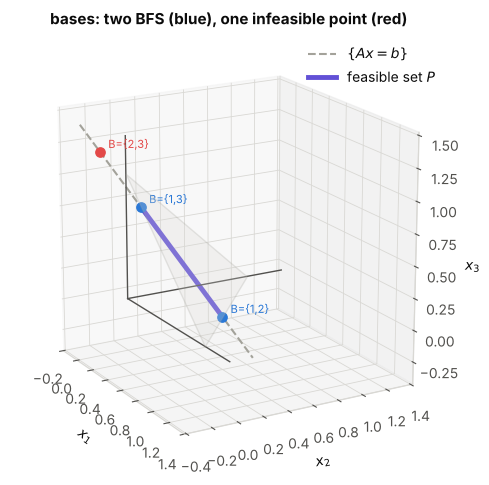

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from itertools import combinations

A = np.array([[1, 1, 1], [1, -1, 0]], float); b = np.array([1, 0.2])
m, n = A.shape
points = []
for B in combinations(range(n), m):
    AB = A[:, B]
    if abs(np.linalg.det(AB)) < 1e-12:
        print(B, "not a basis"); continue
    x = np.zeros(n); x[list(B)] = np.linalg.solve(AB, b)
    points.append((B, x, bool(np.all(x >= -1e-12))))
    print("B =", tuple(j + 1 for j in B), " x =", x.round(4), " BFS" if points[-1][2] else " infeasible")

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
t = np.linspace(-0.3, 0.55, 2)
ax.plot(t + 0.2, t, 0.8 - 2 * t, color=FAINT, lw=1.5, ls="--", label="$\\{Ax = b\\}$")
ts = np.array([0, 0.4]); ax.plot(ts + 0.2, ts, 0.8 - 2 * ts, color=VIOLET, lw=3.5, label="feasible set $P$")
for B, x, ok in points:
    ax.scatter(*x, color=BLUE if ok else RED, s=45, depthshade=False)
    ax.text(*(x + 0.04), "B={%s}" % ",".join(str(j + 1) for j in B), fontsize=8, color=BLUE if ok else RED)
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
ax.add_collection3d(Poly3DCollection([np.eye(3)], facecolor=GRID, alpha=0.25, edgecolor=FAINT))
for i in range(3):
    ax.plot(*np.c_[np.zeros(3), 1.3 * np.eye(3)[i]], color=MUTED, lw=1)
ax.zaxis.set_rotate_label(False)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$", rotation=0)
ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=18, azim=-30); ax.legend(loc="upper right")
ax.set_title("bases: two BFS (blue), one infeasible point (red)")
plt.tight_layout(); plt.show()


## 2\. Optimal Basic Feasible Solutions

::: {#lem-better-bfs}
## Every Feasible Solution Is Matched by a BFS

Suppose $P \ne \emptyset$ and $c^{\mathsf T}x$ is bounded above on $P$. Then for every $x \in P$ there is a BFS $\tilde x$ with $c^{\mathsf T}\tilde x \ge c^{\mathsf T}x$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-better-bfs
Among all feasible $x'$ with $c^{\mathsf T}x' \ge c^{\mathsf T}x$ (a nonempty set: it contains $x$), choose $\tilde x$ with the smallest number of nonzero coordinates, and let $K = \operatorname{supp}\tilde x$. By @prp-bfs-support it suffices to show that the columns $A_j$, $j \in K$, are independent. Suppose not: then some $y \ne 0$ has $Ay = 0$ and $\operatorname{supp} y \subseteq K$ (put the coefficients of a vanishing combination of these columns into $y$). Replacing $y$ by $-y$ if necessary, $c^{\mathsf T}y \ge 0$. For every $t$, $A(\tilde x + ty) = b$, coordinates outside $K$ stay $0$, and for $t \ge 0$, $c^{\mathsf T}(\tilde x + ty) \ge c^{\mathsf T}\tilde x \ge c^{\mathsf T}x$.

*Case 1: some $y_j < 0$.* Let $t_1 = \min\{\tilde x_j/(-y_j) : y_j < 0\}$; then $t_1 > 0$ because $\tilde x_j > 0$ on $K$. The vector $\tilde x + t_1y$ is $\ge 0$ (coordinates with $y_j \ge 0$ do not decrease; for $y_j < 0$ use the minimum) and has a zero at a minimizing index $j \in K$. It is feasible, at least as good as $x$, and has fewer nonzero coordinates than $\tilde x$: a contradiction.

*Case 2: $y \ge 0$.* If $c^{\mathsf T}y > 0$, then $\tilde x + ty$ is feasible for all $t \ge 0$ and $c^{\mathsf T}(\tilde x + ty) \to \infty$, contradicting boundedness. If $c^{\mathsf T}y = 0$, then $-y$ has a negative coordinate (as $y \ne 0$) and $c^{\mathsf T}(-y) = 0 \ge 0$, so Case 1 applied to $-y$ gives a contradiction. $\blacksquare$
:::

::: {#thm-optimal-bfs}
## Existence of an Optimal BFS

If $P \ne \emptyset$ and $c^{\mathsf T}x$ is bounded above on $P$, then the LP has an optimal solution, and some optimal solution is a BFS.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-optimal-bfs
By @lem-better-bfs applied to any $x \in P$, there is at least one BFS, and by @prp-bfs-unique there are finitely many. Let $\hat x$ be a BFS with the largest value $c^{\mathsf T}\hat x$ among them. For every $x \in P$, @lem-better-bfs gives a BFS $\tilde x$ with $c^{\mathsf T}x \le c^{\mathsf T}\tilde x \le c^{\mathsf T}\hat x$. So $\hat x$ is optimal. $\blacksquare$
:::

::: {#cor-lp-trichotomy}
## Every LP Is Infeasible, Unbounded, or Has an Optimum

For every LP exactly one holds: it is infeasible; it is unbounded; it has an optimal solution. Moreover, a feasible LP in equational form whose objective is bounded has an optimal solution among its at most $\binom nm$ basic feasible solutions.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-lp-trichotomy
Write the LP as a maximization and bring it to equational form ([this theorem](equational-form.ipynb#thm-equational-form-conversion)); the three outcomes transfer between the two LPs. If the equations $Ax = b$ have no solution, the LP is infeasible; otherwise remove redundant equations ([this proposition](equational-form.ipynb#prp-independent-rows)), so that $\operatorname{rank} A = m$. If the LP is feasible and not unbounded, its objective is bounded above on $P \ne \emptyset$, and @thm-optimal-bfs gives an optimal BFS. The three outcomes exclude each other by definition. $\blacksquare$
:::

This proves the [statement on the three outcomes](linear-programs.ipynb#thm-lp-trichotomy-statement). It also gives a finite (but very slow) algorithm: try all $\binom nm$ subsets $B$.

## 3\. Basic Feasible Solutions Are the Vertices

::: {#thm-bfs-vertex}
## BFS = Vertex = Extreme Point

For $x \in P$ the following are equivalent:

1. $x$ is a basic feasible solution;
2. $x$ is a [vertex](extreme-points-and-minkowski-theorem.ipynb#def-face-vertex) of $P$;
3. $x$ is an [extreme point](extreme-points-and-minkowski-theorem.ipynb#def-extreme-point) of $P$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-bfs-vertex
($1 \Rightarrow 2$) Let $B$ be a basis of $x$ and define $\bar c_j = 0$ for $j \in B$, $\bar c_j = -1$ for $j \notin B$. For $y \in P$, $\bar c^{\mathsf T}y = -\sum_{j \notin B} y_j \le 0 = \bar c^{\mathsf T}x$, with equality iff $y_N = 0$; by @prp-bfs-unique this holds only for $y = x$. So $\bar c^{\mathsf T}y < \bar c^{\mathsf T}x$ for $y \in P \setminus \{x\}$: $x$ is a vertex.

($2 \Rightarrow 3$) [Every vertex is extreme](extreme-points-and-minkowski-theorem.ipynb#prp-vertex-is-extreme).

($3 \Rightarrow 1$) If the columns $A_j$, $j \in K = \operatorname{supp} x$, were dependent, take $y \ne 0$ with $Ay = 0$, $\operatorname{supp} y \subseteq K$. For $\varepsilon > 0$ small, $x \pm \varepsilon y \ge 0$ (since $x_j > 0$ on $K$ and both vectors vanish off $K$), and $A(x \pm \varepsilon y) = b$. So $x$ is the midpoint of two distinct points of $P$ and not extreme. Hence the columns are independent, and $x$ is a BFS by @prp-bfs-support. $\blacksquare$
:::

::: {.callout-note}
## Another Proof of $2 \Rightarrow 1$
Let $x$ be a vertex: $a^{\mathsf T}y < a^{\mathsf T}x$ for $y \in P \setminus\{x\}$. Then $a^{\mathsf T}y$ is bounded above on $P$, so by @thm-optimal-bfs some BFS maximizes it; the only maximizer is $x$, so $x$ is a BFS.
:::

::: {#cor-vertex-exists}
## Consequences

1. If $P \ne \emptyset$, then $P$ has at least one vertex (apply @thm-optimal-bfs with $c = 0$).
2. If the LP has an optimal solution, it has one at a vertex of $P$ — also when $P$ is unbounded.
3. For a polytope given in equational form, the vertices are the BFS, so a polytope has at most $\binom nm$ vertices.
:::

The simplex method searches for an optimal BFS without listing all of them: it moves from one BFS to a better one.